# Data Preparation

This section load, clean and filter the JobStreet Malaysia dataset to entry-level roles, run EDA, and build/evaluate the skill dictionary.

Run with **Restart > Run All**. Outputs: `../data/jobs_raw.csv`, `../data/jobs_entry.csv`.

# 1. Setup

In [5]:
import sys, re
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import spacy

sys.path.append("..")   # so modules/ is importable from notebooks/
pd.set_option("display.max_colwidth", 120)

# 2. Load data

In [6]:
RAW = Path("../data/jobs_raw.csv")

if RAW.exists():
    df = pd.read_csv(RAW)
else:
    from datasets import load_dataset
    df = load_dataset("azrai99/job-dataset")["train"].to_pandas()
    RAW.parent.mkdir(exist_ok=True)
    df.to_csv(RAW, index=False)

print(df.shape)
print(df.columns.tolist())
df.head()

(59306, 11)
['job_id', 'job_title', 'company', 'descriptions', 'location', 'category', 'subcategory', 'role', 'type', 'salary', 'listingDate']


,job_id,job_title,company,descriptions,location,category,subcategory,role,type,salary,listingDate
0,74630583,Procurement Executive (Contract),Coca-Cola Bottlers (Malaysia) Sdn Bhd,"Position Purpose\nManage aspects of procurement including supplier management, contract management, and vendor perfo...",Negeri Sembilan,"Manufacturing, Transport & Logistics","Purchasing, Procurement & Inventory",procurement-executive,Contract/Temp,NaN,2024-03-21T05:58:35Z
1,74660602,Account Executive/ Assistant,Acoustic & Lighting System Sdn Bhd,We are looking for a Account Executive/ Assistant to join our team.\nWhat you will get when you join us:\nFair work ...,Petaling,Accounting,Bookkeeping & Small Practice Accounting,executive-assistant,Full time,"RM 2,800 – RM 3,200 per month",2024-03-22T06:52:57Z
2,74655679,"Data Analyst - Asset Management, SPX Express",Shopee Mobile Malaysia Sdn Bhd,Performs detailed data analysis on existing spendings / consumptions of SPX and identifies cost saving areas.\nPlan ...,Klang District,"Manufacturing, Transport & Logistics",Analysis & Reporting,asset-management-analyst,Full time,NaN,2024-03-22T04:22:43Z
3,74657624,Service Engineer,Sun Medical Systems Sdn Bhd,"You are important for troubleshooting, installation, maintenance and service repair needs on designated equipment.\n...",Petaling,Engineering,Electrical/Electronic Engineering,services-engineer,Full time,"RM 3,000 – RM 3,500 per month",2024-03-22T05:32:09Z
4,74679363,Purchasing Executive,Magnet Security & Automation Sdn. Bhd.,"MAG is a trailblazer in the industry, boasting an extensive track record of over four decades, rich in technical exp...",Hulu Langat,"Manufacturing, Transport & Logistics","Purchasing, Procurement & Inventory",purchasing-executive,Full time,"RM 2,800 – RM 3,500 per month",2024-03-23T03:56:39Z


# 3. Inspect

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59306 entries, 0 to 59305
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   job_id        59306 non-null  int64
 1   job_title     59306 non-null  str  
 2   company       59306 non-null  str  
 3   descriptions  59306 non-null  str  
 4   location      59306 non-null  str  
 5   category      59306 non-null  str  
 6   subcategory   59306 non-null  str  
 7   role          57370 non-null  str  
 8   type          59306 non-null  str  
 9   salary        26641 non-null  str  
 10  listingDate   59306 non-null  str  
dtypes: int64(1), str(10)
memory usage: 121.4 MB


In [8]:
print("Missing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
job_id              0
job_title           0
company             0
descriptions        0
location            0
category            0
subcategory         0
role             1936
type                0
salary          32665
listingDate         0
dtype: int64

Duplicate rows: 0


In [9]:
df.sample(3, random_state=1).T

,11516,209,1609
job_id,74019850,74598206,74610214
job_title,Office Admin Assistant,Junior Chemical Process (Beneficiation Direction),General Clerk & Site Supervisor
company,SIN-KUNG LOGISTICS BERHAD,Esteel Enterprise Sabah Sdn Bhd,Cyco Fire Tech Sdn Bhd
descriptions,"Job Description:\nAs an Office Admin Assistant, you will be responsible for providing administrative support to ensu...",Responsibilities:\n• Production Process Design: Assist in designing and optimizing mining processing production proc...,"Assist on procurement and documentation.\nIssuing and record Confirmation Order, Delivery Order and Invoices Purchas..."
location,Shah Alam/Subang,Sipitang District,Kajang/Bangi/Serdang
category,Administration & Office Support,Engineering,Administration & Office Support
subcategory,Administrative Assistants,Chemical Engineering,Administrative Assistants
role,office-administrator,NaN,site-supervisor
type,Full time,Full time,Full time
salary,NaN,"RM 2,500 – RM 3,500 per month","RM 1,800 – RM 2,500 per month"


# 4. Clean

In [10]:
n0 = len(df)
df = df.drop_duplicates(subset=["job_title", "company", "descriptions"])
n1 = len(df)
df = df[df["descriptions"].str.strip().str.len() > 100]
n2 = len(df)
print(f"raw: {n0} | after de-duplication: {n1} | after removing short/empty descriptions: {n2}")

df["listingDate"] = pd.to_datetime(df["listingDate"])
df["descriptions"] = df["descriptions"].str.replace(r"\s+", " ", regex=True).str.strip()

raw: 59306 | after de-duplication: 55868 | after removing short/empty descriptions: 55785


# 5. Entry-level filter

## 5.1 Required years of experience
The regex needed iterative refinement. Two false-positive sources were found and removed:
- **Age requirements** ("at least 18 years old") were read as 18 years of experience.
- **Company history** ("18 years of experience in facilities management") was read as a candidate requirement.

Final rule: strip age phrases first, then require "experience" shortly after the number of years.

In [11]:
def min_years(text):
    text = text.lower()

    # strip age-related phrases first
    text = re.sub(r"\d+\s*years?\s*(old|of age|and above|& above)", "", text)
    text = re.sub(r"(age|aged)\s*:?\s*\d+", "", text)

    # years followed by "experience" (a few words allowed in between)
    m = re.findall(r"(\d+)\s*(?:\+|-\s*\d+)?\s*(?:years?|yrs?)[^.]{0,25}?experience", text)
    nums = [int(x) for x in m if int(x) < 20]
    return min(nums) if nums else None


# regression tests for the bugs above
age_cases = [
    "Job Requirements Min. 18 years and above; Good communication skills",
    "Must be at least 18 years old. Fresh graduates are encouraged to apply.",
    "Greets customers... High school diploma or equivalent At least 18 years old",
    "At least 18 years old and above 4) Dedicated and pleasant personality",
]
exp_cases = [
    "At least 5 years of working experience preferably in managing F&B outlets",
    "Minimum 5 years' experience on construction projects",
    "5 years\u2019 experience in technical selling in Azure and M365 solutions",
]
assert all(min_years(s) is None for s in age_cases)
assert all(min_years(s) == 5 for s in exp_cases)

df["min_years"] = df["descriptions"].apply(min_years)
df["min_years"].value_counts(dropna=False).sort_index()

min_years
0.0       116
1.0      5703
2.0      7106
3.0      5978
4.0      1049
5.0      4503
6.0       405
7.0       407
8.0       665
9.0        19
10.0      776
11.0        3
12.0       83
13.0        5
14.0        3
15.0      165
16.0        6
17.0        1
18.0        6
NaN     28786
Name: count, dtype: int64

## 5.2 Title and keyyword rules
`assistant` and `associate` are excluded from the entry pattern (they also appear in senior titles such as *Assistant Manager*). `specialist` is excluded from the senior pattern because it is a mixed role name in Malaysian postings.

In [12]:
title = df["job_title"].fillna("").astype("string").str.lower()
description = df["descriptions"].fillna("").astype("string").str.lower()

senior_pattern = (
    r"\b(?:senior|sr\.?|lead|principal|manager|director|head|chief|"
    r"supervisor|vice president|vp|consultant|architect)\b"
)
entry_pattern = (
    r"\b(?:fresh graduate(?:s)?|entry[- ]level|no experience|"
    r"without experience|junior|trainee|intern|graduate program)\b"
)

df["is_senior_title"] = title.str.contains(senior_pattern, regex=True, na=False)
df["entry_signal"] = (
    title.str.contains(entry_pattern, regex=True, na=False)
    | description.str.contains(entry_pattern, regex=True, na=False)
)

## 5.3 Apply the filter
Entry-level = not a senior title AND (stated experience <= 1 year, OR no stated experience but an entry-level signal).

In [13]:
entry_df = df[
    ~df["is_senior_title"]
    & (
        (df["min_years"] <= 1)
        | (df["min_years"].isna() & df["entry_signal"])
    )
].copy()

print(len(entry_df), "of", len(df), f"({len(entry_df)/len(df)*100:.1f}%)")
entry_df["category"].value_counts().head(10)

11206 of 55785 (20.1%)


category
Accounting                                1954
Administration & Office Support           1761
Information & Communication Technology    1276
Engineering                               1231
Sales                                      915
Manufacturing, Transport & Logistics       717
Human Resources & Recruitment              569
Marketing & Communications                 546
Call Centre & Customer Service             413
Banking & Financial Services               383
Name: count, dtype: int64

## 5.4 Validation by manual inspection

In [17]:
#included rows (should all look entry-level)
entry_df.sample(15, random_state=1)[["job_title", "min_years", "entry_signal"]]

,job_title,min_years,entry_signal
31517,Videographer cum Video Editor,NaN,True
47669,"Telemarketer (B2B) Earn Up To RM6,000 Per Month!",NaN,True
32506,Sales Executive,NaN,True
41753,Brand Activation Executive - Fresh Grads Welcome,NaN,True
45019,Content Creator (Full Time / Interns),NaN,True
32262,Management Trainee (Product),NaN,True
50434,Customer Service Assistant,1.0,False
47179,Sales Executive,NaN,True
51074,FSQR Lab Technician,NaN,True
15547,P&G Sales Internship Program 2023/2024,NaN,True


In [18]:
# excluded senior titles (should all look senior)
df[df["is_senior_title"]][["job_title"]].sample(10, random_state=1)

,job_title
21454,Design Architect/Drafter with 3D And 2D
9588,L&D Manager
33861,Investment Manager (AmREIT Managers Sdn Bhd)
10803,Senior Credit Assessment/Management/Review Analyst
58275,Sales Manager
18739,Audit Associate / Audit Senior
53187,"Finance Manager (2 position available: Petaling Jaya, Sg Long)"
28323,Audit/Accounts Senior Executive
39890,Senior Accountant
1233,[Hybrid] R2R Senior Specialist


In [19]:
entry_df.to_csv("../data/jobs_entry.csv", index=False)

# 6. Exploratonary data analysis

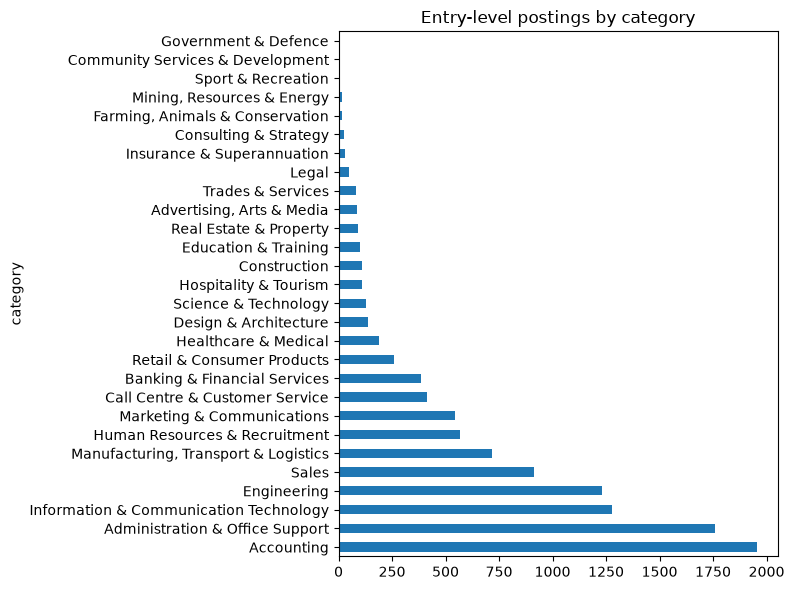

In [20]:
entry_df["category"].value_counts().plot(kind="barh", figsize=(8, 6), title="Entry-level postings by category")
plt.tight_layout()
plt.show()

Accounting, Administration, ICT and Engineering dominate. Several categories (e.g. Government & Defence, Community Services) have almost no entry-level postings.

In [22]:
entry_df["location"].value_counts().head(15)

location
Kuala Lumpur                2417
Petaling                    2070
Johor Bahru District         901
Selangor                     586
Shah Alam/Subang             506
Penang Island                357
Seberang Perai               333
Penang                       320
Kuala Lumpur City Centre     299
Klang District               264
Hulu Langat                  218
Kajang/Bangi/Serdang         196
Johor                        153
Kuching Division             132
Kinta District               126
Name: count, dtype: int64

Postings are concentrated in the Klang Valley (Kuala Lumpur, Petaling, Selangor) and Johor Bahru. East Malaysia is thinly represented. This is a limitation of the platform's coverage.

In [23]:
entry_df["descriptions"].str.len().describe()

count    11206.000000
mean      1650.367660
std        955.874238
min        102.000000
25%       1008.250000
50%       1441.500000
75%       2052.000000
max      12332.000000
Name: descriptions, dtype: float64

Mean about 1,650 characters, median about 1,440, max over 12,000. Longer descriptions will be truncated by the SBERT model, so the embedding strategy must be decided explicitly (full text vs. requirements section only).

In [24]:
entry_df["type"].value_counts()

type
Full time          9900
Contract/Temp      1066
Casual/Vacation     149
Part time            91
Name: count, dtype: int64

In [25]:
entry_df["subcategory"].value_counts().head(15)

subcategory
Administrative Assistants                  1274
Bookkeeping & Small Practice Accounting     970
Electrical/Electronic Engineering           397
Consulting & Generalist HR                  357
Account & Relationship Management           338
Purchasing, Procurement & Inventory         306
Developers/Programmers                      291
Financial Accounting & Reporting            276
Sales Representatives/Consultants           269
Marketing Communications                    259
Help Desk & IT Support                      258
Customer Service - Call Centre              258
Other                                       242
Mechanical Engineering                      225
Audit - External                            177
Name: count, dtype: int64

# 7. Skill dictionary construction
Corpus-driven: candidate terms are mined from the full entry-level dataset, then reviewed manually (keep / merge into a canonical term / drop). The reviewed result is stored in `modules/skill_dictionary.py`.

## 7.1 Candidate mining: context patterns

In [26]:
context_pattern = re.compile(
    r"(?:experience (?:with|in)|proficient in|knowledge of|familiar(?:ity)? with|skilled in)\s+([a-zA-Z0-9\+\#\.\s]{2,40}?)(?:[.,;\n]|and\b)",
    re.IGNORECASE,
)

candidate_counter = Counter()
for desc in entry_df["descriptions"]:
    for m in context_pattern.findall(desc.lower()):
        term = m.strip()
        if 2 <= len(term) <= 40:
            candidate_counter[term] += 1

print(len(candidate_counter), "distinct candidate terms")
candidate_counter.most_common(400)

3574 distinct candidate terms


[('microsoft office', 169),
 ('related field', 133),
 ('the related field', 120),
 ('english', 119),
 ('ms office', 82),
 ('sales', 79),
 ('logistics', 58),
 ('accounting', 57),
 ('microsoft excel', 50),
 ('written', 46),
 ('both written', 42),
 ('microsoft word', 41),
 ('microsoft office applications', 36),
 ('customer service', 32),
 ('mandarin', 28),
 ('a similar role', 28),
 ('accounting software', 23),
 ('accounting principles', 23),
 ('digital marketing', 22),
 ('the related field is required', 21),
 ('ms excel', 19),
 ('autocad', 19),
 ('excel', 19),
 ('spoken', 18),
 ('finance', 18),
 ('social media platforms', 18),
 ('microsoft office suite', 16),
 ('sql', 16),
 ('ms office applications', 16),
 ('audit', 14),
 ('a related field', 14),
 ('similar capacity', 14),
 ('a logistics services company', 14),
 ('ms word', 13),
 ('a similar position', 13),
 ('project management', 13),
 ('purchasing', 13),
 ('relevant field', 13),
 ('marketing', 13),
 ('accounting standards', 12),
 ('rela

## 7.2 Manual review
Candidates were reviewed by hand: real skills kept, spelling variants merged into one canonical term (e.g. *ms office* -> *microsoft office*), and sentence fragments dropped (e.g. *the related field*, *a similar role*). Language skills (English, Mandarin, Bahasa Malaysia, ...) are kept in a separate list.

# 8. Dictionary coverage evaluation and targeted expansion
Evaluation and expansion are iterated: coverage is measured, weak categories are mined for new terms, the terms are reviewed manually and added to `modules/skill_dictionary.py`, then coverage is measured again. After editing the module, re-run from 8.1.

## 8.1 Overall coverage

In [37]:
import importlib
import modules.skill_dictionary as sd
importlib.reload(sd)   # pick up edits to skill_dictionary.py without restarting the kernel
from modules.skill_dictionary import (
    SKILLS, ALIASES, LANGUAGES, LANGUAGE_ALIASES, build_matcher, extract_terms
)

nlp = spacy.load("en_core_web_sm")
skill_matcher = build_matcher(nlp, SKILLS, ALIASES)
lang_matcher = build_matcher(nlp, LANGUAGES, LANGUAGE_ALIASES)

entry_df["skills"] = entry_df["descriptions"].apply(lambda t: extract_terms(t, nlp, skill_matcher))
entry_df["languages"] = entry_df["descriptions"].apply(lambda t: extract_terms(t, nlp, lang_matcher))
entry_df["n_skills"] = entry_df["skills"].apply(len)

zero = (entry_df["n_skills"] == 0).sum()
print(f"Dictionary size: {len(SKILLS)} skills, {len(ALIASES)} aliases, {len(LANGUAGES)} languages")
print(f"{zero} of {len(entry_df)} postings with zero skills matched ({zero/len(entry_df)*100:.1f}%)")
entry_df["n_skills"].describe()

Dictionary size: 135 skills, 60 aliases, 6 languages
590 of 11206 postings with zero skills matched (5.3%)


count    11206.000000
mean         3.907282
std          2.391541
min          0.000000
25%          2.000000
50%          4.000000
75%          5.000000
max         19.000000
Name: n_skills, dtype: float64

## 8.2 Coverage by category
Zero-match rate shows where the dictionary finds nothing; mean skills per posting shows how deep the coverage is.

In [38]:
coverage = pd.DataFrame({
    "n": entry_df["category"].value_counts(),
    "zero_pct": entry_df.groupby("category")["n_skills"].apply(lambda s: (s == 0).mean() * 100),
    "mean_skills": entry_df.groupby("category")["n_skills"].mean(),
}).round(1).sort_values("zero_pct", ascending=False)
coverage

,n,zero_pct,mean_skills
category,,,
Sport & Recreation,8,50.0,0.8
"Farming, Animals & Conservation",17,35.3,1.5
Education & Training,101,24.8,2.2
Hospitality & Tourism,109,23.9,1.7
Legal,48,18.8,2.1
Community Services & Development,6,16.7,2.8
Healthcare & Medical,191,15.7,2.7
Construction,108,13.9,3.3
Trades & Services,80,13.8,2.3


## 8.3 Weak categories
Rule: at least 20% of postings with zero matches **and** at least 40 postings. Smaller categories are too small to mine reliably and are reported as a limitation instead.

In [39]:
weak_categories = coverage[(coverage["zero_pct"] >= 20) & (coverage["n"] >= 40)].index.tolist()
print(weak_categories)
coverage.loc[weak_categories]

['Education & Training', 'Hospitality & Tourism']


,n,zero_pct,mean_skills
category,,,
Education & Training,101,24.8,2.2
Hospitality & Tourism,109,23.9,1.7


## 8.4 Targeted mining in weak categories
Noun phrases are ranked by how much more often they occur in the weak categories than elsewhere. To filter out one employer's repeated postings, a phrase must be used by at least 3 different companies. Terms already in the dictionary are hidden.

In [40]:
nlp_fast = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
strip_det = re.compile(r"^(the|a|an|our|your|their|this|that|any)\s+")

def mine_phrases(frame):
    """Return phrase -> posting count, and phrase -> set of companies using it."""
    counts, companies = Counter(), {}
    docs = nlp_fast.pipe(frame["descriptions"].str.lower(), batch_size=100)
    for company, doc in zip(frame["company"], docs):
        for ch in doc.noun_chunks:
            t = strip_det.sub("", ch.text.strip())
            if 2 <= len(t.split()) <= 4 and len(t) <= 40:
                counts[t] += 1
                companies.setdefault(t, set()).add(company)
    return counts, companies

weak_mask = entry_df["category"].isin(weak_categories)
weak_df, rest_df = entry_df[weak_mask], entry_df[~weak_mask]
print(len(weak_df), "weak-category postings |", len(rest_df), "others")

weak_c, weak_comp = mine_phrases(weak_df)
rest_c, _ = mine_phrases(rest_df)

MIN_POSTINGS, MIN_COMPANIES = 5, 3
known = set(SKILLS) | set(ALIASES)

rows = []
for phrase, n in weak_c.items():
    if n < MIN_POSTINGS or len(weak_comp[phrase]) < MIN_COMPANIES or phrase in known:
        continue
    expected = rest_c.get(phrase, 0) / len(rest_df) * len(weak_df)   # expected count if no category effect
    rows.append((phrase, n, len(weak_comp[phrase]), round(n / (expected + 1), 2)))

candidates = pd.DataFrame(rows, columns=["phrase", "postings", "companies", "score"]).sort_values("score", ascending=False)
candidates.head(80)

210 weak-category postings | 10996 others


,phrase,postings,companies,score
21,primary students,9,4,9.00
42,f&b industry,11,5,8.19
50,special requests,8,5,7.57
46,all guests,9,4,6.89
26,teaching experience,7,5,6.87
...,...,...,...,...
10,administrative support,5,4,0.72
34,key responsibilities,8,6,0.71
49,fresh graduate,14,11,0.69
27,bachelor's degree,11,9,0.62


## 8.5 Iteration log


| Round | Change to dictionary | Data | Zero-match rate |
|---|---|---|---|
| 1 | Seed list + first review (about 100 terms) | 400 per category sample (5,424 postings) | 13.0% |
| 2 | Full-dataset review + aliases, `modules/skill_dictionary.py` | Full entry-level set (11,206) | 6.4% |
| 3 | Weak-category additions (education, construction, healthcare, F&B) | Full entry-level set (11,206) | 5.3% |